# Retail Sales Data Analysis & Business Performance Report

## 1. Project Overview

This project analyzes retail sales transaction data to understand sales performance, profitability, product performance, regional trends, customer behavior, and sales channels.

### Objectives

- Clean and validate the retail sales dataset
- Analyze revenue, profit, orders, and units sold
- Identify top-performing products and categories
- Analyze regional and city-wise sales performance
- Analyze monthly sales and profit trends
- Understand customer purchasing behavior
- Generate actionable business insights

## 2. Data Loading

The retail sales dataset was provided in CSV format. Pandas was used to load the dataset into a DataFrame for further analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df = pd.read_csv("../data/raw_sales_data.csv")
df.head()

,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,City,Sales Channel,Quantity,Unit Price,Discount,Revenue,Cost,Profit,Payment Method
0,ORD00834,15-07-2026,CUST0329,Nisha Shah,Power Bank,Electronics,North,Chandigarh,Online,1,1299,5.0,1234.05,700,534.05,Net Banking
1,ORD01389,22-02-2025,CUST0296,Ananya Kulkarni,Premium Rice 5kg,Grocery,South,Bengaluru,Online,3,699,10.0,1887.30,1440,447.30,Debit Card
2,ORD01305,25-07-2025,CUST0230,Isha Singh,Wireless Headphones,Electronics,West,Pune,Offline,5,2499,0.0,12495.00,7500,4995.00,Credit Card
3,ORD01195,12-06-2026,CUST0113,Sneha Kumar,Makeup Kit,Beauty,North,Chandigarh,Online,2,2499,0.0,4998.00,2800,2198.00,Net Banking
4,ORD01250,24-12-2025,CUST0333,Nisha Jadhav,Running Shoes,Fashion,North,Chandigarh,Online,1,2999,5.0,2849.05,1700,1149.05,UPI


## 3. Data Understanding

The dataset was inspected to understand its size, structure, columns, data types, and available information before starting the cleaning process.

In [3]:
df.shape

(2000, 16)

In [4]:
df.columns

Index(['Order ID', 'Order Date', 'Customer ID', 'Customer Name', 'Product',
       'Category', 'Region', 'City', 'Sales Channel', 'Quantity', 'Unit Price',
       'Discount', 'Revenue', 'Cost', 'Profit', 'Payment Method'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        2000 non-null   str    
 1   Order Date      2000 non-null   str    
 2   Customer ID     2000 non-null   str    
 3   Customer Name   1992 non-null   str    
 4   Product         2000 non-null   str    
 5   Category        2000 non-null   str    
 6   Region          2000 non-null   str    
 7   City            1994 non-null   str    
 8   Sales Channel   2000 non-null   str    
 9   Quantity        2000 non-null   int64  
 10  Unit Price      2000 non-null   int64  
 11  Discount        1996 non-null   float64
 12  Revenue         2000 non-null   float64
 13  Cost            2000 non-null   int64  
 14  Profit          2000 non-null   float64
 15  Payment Method  1995 non-null   str    
dtypes: float64(3), int64(3), str(10)
memory usage: 413.3 KB


### Numerical and Categorical Columns

In [70]:
numerical_columns = df.select_dtypes(include=np.number).columns

categorical_columns = df.columns[df.dtypes == "object"]

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['Quantity', 'Unit Price', 'Discount', 'Revenue', 'Cost', 'Profit']

Categorical Columns:
[]


### Order Date Range

In [71]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    dayfirst=True,
    errors="coerce"
)

print("Minimum Order Date:", df["Order Date"].min())
print("Maximum Order Date:", df["Order Date"].max())

Minimum Order Date: 2025-01-01 00:00:00
Maximum Order Date: 2026-08-31 00:00:00


## 4. Data Cleaning

Data cleaning was performed to improve data quality and ensure reliable analysis.

The following checks were performed:

- Missing values
- Duplicate orders
- Invalid quantities
- Invalid unit prices
- Date format
- Invalid discounts
- Revenue calculation
- Profit calculation

In [6]:
df.isnull().sum()

Order ID          0
Order Date        0
Customer ID       0
Customer Name     8
Product           0
Category          0
Region            0
City              6
Sales Channel     0
Quantity          0
Unit Price        0
Discount          4
Revenue           0
Cost              0
Profit            0
Payment Method    5
dtype: int64

In [7]:
df['Customer Name'] = df['Customer Name'].fillna('Unknown')
df['City'] = df['City'].fillna('Unknown')
df['Discount'] = df['Discount'].fillna(0)
df['Payment Method'] = df['Payment Method'].fillna('Unknown')

print("Missing values handled successfully")

Missing values handled successfully


In [8]:
df.isnull().sum()

Order ID          0
Order Date        0
Customer ID       0
Customer Name     0
Product           0
Category          0
Region            0
City              0
Sales Channel     0
Quantity          0
Unit Price        0
Discount          0
Revenue           0
Cost              0
Profit            0
Payment Method    0
dtype: int64

In [9]:
df['Order ID'].duplicated().sum()

np.int64(10)

In [10]:
duplicate_orders = df[df['Order ID'].duplicated(keep=False)]

duplicate_orders

,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,City,Sales Channel,Quantity,Unit Price,Discount,Revenue,Cost,Profit,Payment Method
89,ORD00833,12-11-2025,CUST0449,Ananya Kumar,Casual Shirt,Fashion,South,Bengaluru,Online,5,1499,0.0,7495.00,4000,3495.00,Net Banking
186,ORD01241,09-06-2026,CUST0386,Isha Jadhav,Air Fryer,Home & Kitchen,East,Ranchi,Offline,1,5499,5.0,5224.05,3600,1624.05,Debit Card
326,ORD01513,14-08-2026,CUST0122,Isha Sharma,Face Wash,Beauty,East,Kolkata,Online,2,499,5.0,948.10,500,448.10,UPI
406,ORD00287,27-10-2025,CUST0059,Vikram Verma,USB-C Charger,Electronics,North,Jaipur,Offline,1,899,5.0,854.05,450,404.05,Credit Card
624,ORD01513,14-08-2026,CUST0122,Isha Sharma,Face Wash,Beauty,East,Kolkata,Online,2,499,5.0,948.10,500,448.10,UPI
657,ORD00833,12-11-2025,CUST0449,Ananya Kumar,Casual Shirt,Fashion,South,Bengaluru,Online,5,1499,0.0,7495.00,4000,3495.00,Net Banking
729,ORD01529,07-04-2025,CUST0019,Sakshi Singh,Bluetooth Speaker,Electronics,West,Mumbai,Offline,2,1999,0.0,3998.00,2300,1698.00,Net Banking
804,ORD00272,25-03-2026,CUST0289,Kavya Jadhav,Jeans,Fashion,East,Patna,Online,2,2199,5.0,4178.10,2500,1678.10,UPI
922,ORD01241,09-06-2026,CUST0386,Isha Jadhav,Air Fryer,Home & Kitchen,East,Ranchi,Offline,1,5499,5.0,5224.05,3600,1624.05,Debit Card
1072,ORD01484,03-02-2026,CUST0434,Priya Pawar,Premium Rice 5kg,Grocery,East,Ranchi,Online,2,699,20.0,1118.40,960,158.40,UPI


In [11]:
duplicate_orders

,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,City,Sales Channel,Quantity,Unit Price,Discount,Revenue,Cost,Profit,Payment Method
89,ORD00833,12-11-2025,CUST0449,Ananya Kumar,Casual Shirt,Fashion,South,Bengaluru,Online,5,1499,0.0,7495.00,4000,3495.00,Net Banking
186,ORD01241,09-06-2026,CUST0386,Isha Jadhav,Air Fryer,Home & Kitchen,East,Ranchi,Offline,1,5499,5.0,5224.05,3600,1624.05,Debit Card
326,ORD01513,14-08-2026,CUST0122,Isha Sharma,Face Wash,Beauty,East,Kolkata,Online,2,499,5.0,948.10,500,448.10,UPI
406,ORD00287,27-10-2025,CUST0059,Vikram Verma,USB-C Charger,Electronics,North,Jaipur,Offline,1,899,5.0,854.05,450,404.05,Credit Card
624,ORD01513,14-08-2026,CUST0122,Isha Sharma,Face Wash,Beauty,East,Kolkata,Online,2,499,5.0,948.10,500,448.10,UPI
657,ORD00833,12-11-2025,CUST0449,Ananya Kumar,Casual Shirt,Fashion,South,Bengaluru,Online,5,1499,0.0,7495.00,4000,3495.00,Net Banking
729,ORD01529,07-04-2025,CUST0019,Sakshi Singh,Bluetooth Speaker,Electronics,West,Mumbai,Offline,2,1999,0.0,3998.00,2300,1698.00,Net Banking
804,ORD00272,25-03-2026,CUST0289,Kavya Jadhav,Jeans,Fashion,East,Patna,Online,2,2199,5.0,4178.10,2500,1678.10,UPI
922,ORD01241,09-06-2026,CUST0386,Isha Jadhav,Air Fryer,Home & Kitchen,East,Ranchi,Offline,1,5499,5.0,5224.05,3600,1624.05,Debit Card
1072,ORD01484,03-02-2026,CUST0434,Priya Pawar,Premium Rice 5kg,Grocery,East,Ranchi,Online,2,699,20.0,1118.40,960,158.40,UPI


In [12]:
df = df.drop_duplicates(subset=['Order ID'], keep='first')

print("Duplicate orders removed successfully!")

Duplicate orders removed successfully!


In [13]:
print("Rows after cleaning:", len(df))
print("Duplicate Order IDs:", df['Order ID'].duplicated().sum())

Rows after cleaning: 1990
Duplicate Order IDs: 0


In [14]:
df[df['Quantity'] <= 0]

,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,City,Sales Channel,Quantity,Unit Price,Discount,Revenue,Cost,Profit,Payment Method
62,ORD00709,11-09-2025,CUST0382,Meera Shah,Dry Fruits Pack,Grocery,North,Delhi,Online,-2,1299,10.0,4676.40,3400,1276.40,Net Banking
1801,ORD01400,19-04-2025,CUST0023,Riya Deshmukh,Electric Kettle,Home & Kitchen,East,Kolkata,Offline,-2,1799,5.0,5127.15,3150,1977.15,Net Banking
1947,ORD00136,04-07-2026,CUST0361,Arjun Kumar,Cookware Set,Home & Kitchen,South,Hyderabad,Online,-2,3999,10.0,7198.20,5000,2198.20,Debit Card


### Duplicate Customer Records

Customer IDs were checked for consistency to identify whether a single customer ID is associated with multiple customer names.

In [72]:
customer_check = (
    df.groupby('Customer ID')['Customer Name']
    .nunique()
)

duplicate_customer_ids = customer_check[customer_check > 1]

print("Customer IDs with multiple names:", len(duplicate_customer_ids))

Customer IDs with multiple names: 8


In [73]:
customer_duplicates = df[
    df['Customer ID'].isin(duplicate_customer_ids.index)
][['Customer ID', 'Customer Name']].sort_values('Customer ID')

customer_duplicates

,Customer ID,Customer Name
69,CUST0013,Sneha Singh
792,CUST0013,Sneha Singh
1225,CUST0013,Sneha Singh
1374,CUST0013,Sneha Singh
1570,CUST0013,Unknown
386,CUST0021,Nisha Jadhav
562,CUST0021,Nisha Jadhav
694,CUST0021,Unknown
902,CUST0021,Nisha Jadhav
1554,CUST0021,Nisha Jadhav


In [74]:
# Replace Unknown customer names using the known name for each Customer ID

customer_name_map = (
    df[df['Customer Name'] != 'Unknown']
    .groupby('Customer ID')['Customer Name']
    .first()
)

df['Customer Name'] = df.apply(
    lambda row: customer_name_map.get(row['Customer ID'], row['Customer Name'])
    if row['Customer Name'] == 'Unknown'
    else row['Customer Name'],
    axis=1
)

print("Unknown customer names remaining:",
      (df['Customer Name'] == 'Unknown').sum())

Unknown customer names remaining: 0


In [75]:
customer_check = (
    df.groupby('Customer ID')['Customer Name']
    .nunique()
)

duplicate_customer_ids = customer_check[customer_check > 1]

print("Customer IDs with multiple names:", len(duplicate_customer_ids))

Customer IDs with multiple names: 0


In [76]:
print("Unknown Customer Names:",
      (df['Customer Name'] == 'Unknown').sum())

Unknown Customer Names: 0


In [77]:
df.to_csv("../data/cleaned_sales_data.csv", index=False)

print("Final cleaned dataset saved successfully!")

Final cleaned dataset saved successfully!


In [15]:
df = df[df['Quantity'] > 0]

print("Invalid quantity records removed!")

Invalid quantity records removed!


In [16]:
print("Rows after quantity cleaning:", len(df))
print("Invalid quantities:", (df['Quantity'] <= 0).sum())

Rows after quantity cleaning: 1987
Invalid quantities: 0


In [17]:
df[df['Unit Price'] <= 0]

,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,City,Sales Channel,Quantity,Unit Price,Discount,Revenue,Cost,Profit,Payment Method
302,ORD01356,17-10-2025,CUST0428,Rahul Joshi,Electric Kettle,Home & Kitchen,East,Kolkata,Online,2,-999,15.0,3058.3,2100,958.3,UPI
588,ORD01786,04-07-2025,CUST0015,Aditi Verma,Wireless Headphones,Electronics,West,Pune,Offline,2,-999,0.0,4998.0,3000,1998.0,Debit Card


In [18]:
df = df[df['Unit Price'] > 0]

print("Invalid unit price records removed!")

Invalid unit price records removed!


In [19]:
print("Rows after price cleaning:", len(df))
print("Invalid unit prices:", (df['Unit Price'] <= 0).sum())

Rows after price cleaning: 1985
Invalid unit prices: 0


In [20]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    dayfirst=True,
    errors='coerce'
)

print("Order Date converted successfully!")

Order Date converted successfully!


In [21]:
df['Order Date'].dtype

dtype('<M8[us]')

In [22]:
df['Order Date'].min(), df['Order Date'].max()

(Timestamp('2025-01-01 00:00:00'), Timestamp('2026-08-31 00:00:00'))

In [23]:
df['Order Date'].isna().sum()

np.int64(0)

In [24]:
df[(df['Discount'] < 0) | (df['Discount'] > 100)]

,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,City,Sales Channel,Quantity,Unit Price,Discount,Revenue,Cost,Profit,Payment Method


In [25]:
df[['Revenue', 'Cost', 'Profit']].describe()

,Revenue,Cost,Profit
count,1985.000000,1985.000000,1985.000000
mean,3725.006952,2422.871537,1302.135416
std,3402.312539,2330.358812,1156.346636
min,399.200000,250.000000,24.250000
25%,1499.000000,900.000000,479.150000
50%,2599.000000,1600.000000,949.000000
75%,4857.300000,3150.000000,1698.000000
max,27495.000000,18000.000000,9495.000000


In [26]:
profit_check = (df['Revenue'] - df['Cost']).round(2) == df['Profit'].round(2)

print("Incorrect profit calculations:", (~profit_check).sum())

Incorrect profit calculations: 0


In [27]:
calculated_revenue = (
    df['Quantity'] *
    df['Unit Price'] *
    (1 - df['Discount'] / 100)
).round(2)

revenue_check = calculated_revenue == df['Revenue'].round(2)

print("Incorrect revenue calculations:", (~revenue_check).sum())

Incorrect revenue calculations: 1


In [28]:
revenue_errors = df[~revenue_check].copy()

revenue_errors[
    ['Order ID', 'Quantity', 'Unit Price', 'Discount', 'Revenue', 'Cost', 'Profit']
]

,Order ID,Quantity,Unit Price,Discount,Revenue,Cost,Profit
884,ORD01715,1,2499,0.0,2374.05,1500,874.05


In [29]:
df.loc[df['Order ID'] == 'ORD01715', 'Revenue'] = (
    df.loc[df['Order ID'] == 'ORD01715', 'Quantity'] *
    df.loc[df['Order ID'] == 'ORD01715', 'Unit Price'] *
    (1 - df.loc[df['Order ID'] == 'ORD01715', 'Discount'] / 100)
)

df.loc[df['Order ID'] == 'ORD01715', 'Profit'] = (
    df.loc[df['Order ID'] == 'ORD01715', 'Revenue'] -
    df.loc[df['Order ID'] == 'ORD01715', 'Cost']
)

print("Revenue and Profit corrected for ORD01715")

Revenue and Profit corrected for ORD01715


In [30]:
calculated_revenue = (
    df['Quantity'] *
    df['Unit Price'] *
    (1 - df['Discount'] / 100)
).round(2)

revenue_check = calculated_revenue == df['Revenue'].round(2)

print("Incorrect revenue calculations:", (~revenue_check).sum())

Incorrect revenue calculations: 0


### 4.1 Final Data Quality Validation

After cleaning, the dataset was validated again to ensure that missing values, duplicate orders, invalid quantities, invalid prices, invalid dates, and invalid discounts were removed or handled appropriately.

In [31]:
print("Rows and Columns:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Order IDs:")
print(df['Order ID'].duplicated().sum())

print("\nInvalid Quantities:")
print((df['Quantity'] <= 0).sum())

print("\nInvalid Unit Prices:")
print((df['Unit Price'] <= 0).sum())

print("\nInvalid Dates:")
print(df['Order Date'].isna().sum())

print("\nInvalid Discounts:")
print(((df['Discount'] < 0) | (df['Discount'] > 100)).sum())

print("\nFinal Validation Completed!")

Rows and Columns: (1985, 16)

Missing Values:
0

Duplicate Order IDs:
0

Invalid Quantities:
0

Invalid Unit Prices:
0

Invalid Dates:
0

Invalid Discounts:
0

Final Validation Completed!


In [32]:
df.to_csv("../data/cleaned_sales_data.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [33]:
total_revenue = df['Revenue'].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 7394263.75


In [34]:
total_profit = df['Profit'].sum()

print("Total Profit:", total_profit)

Total Profit: 2584863.75


In [35]:
total_orders = df['Order ID'].nunique()

print("Total Orders:", total_orders)

Total Orders: 1985


In [36]:
total_units = df['Quantity'].sum()

print("Total Units Sold:", total_units)

Total Units Sold: 4171


In [37]:
aov = total_revenue / total_orders

print("Average Order Value (AOV): ₹", round(aov, 2))

Average Order Value (AOV): ₹ 3725.07


In [38]:
profit_margin = (total_profit / total_revenue) * 100

print("Profit Margin:", round(profit_margin, 2), "%")

Profit Margin: 34.96 %


## Product Performance Analysis

This analysis evaluates product-level and category-level performance using Revenue, Profit, and Profit Margin.

The analysis focuses on:
- Top 10 products by revenue
- Top 10 products by profit
- Lowest-performing products
- Revenue by category
- Profit by category
- Profit margin by category

In [39]:
category_revenue = (
    df.groupby('Category')['Revenue']
      .sum()
      .sort_values(ascending=False)
)

category_revenue

Category
Home & Kitchen    2154376.20
Electronics       1490241.40
Fashion           1283846.20
Sports            1036763.25
Beauty             862528.20
Grocery            566508.50
Name: Revenue, dtype: float64

In [40]:
category_profit = (
    df.groupby('Category')['Profit']
      .sum()
      .sort_values(ascending=False)
)

category_profit

Category
Home & Kitchen    650326.20
Electronics       536841.40
Fashion           513856.20
Sports            388013.25
Beauty            343628.20
Grocery           152198.50
Name: Profit, dtype: float64

In [41]:
category_margin = (
    df.groupby('Category')
      .agg(
          Revenue=('Revenue', 'sum'),
          Profit=('Profit', 'sum')
      )
)

category_margin['Profit Margin %'] = (
    category_margin['Profit'] /
    category_margin['Revenue'] * 100
).round(2)

category_margin.sort_values(
    'Profit Margin %',
    ascending=False
)

,Revenue,Profit,Profit Margin %
Category,,,
Fashion,1283846.20,513856.20,40.02
Beauty,862528.20,343628.20,39.84
Sports,1036763.25,388013.25,37.43
Electronics,1490241.40,536841.40,36.02
Home & Kitchen,2154376.20,650326.20,30.19
Grocery,566508.50,152198.50,26.87


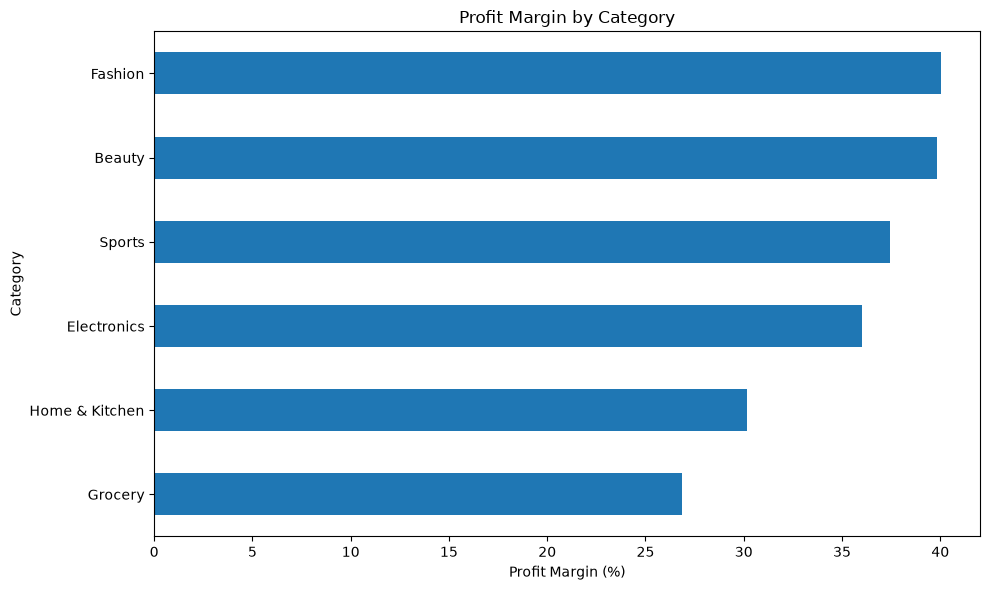

In [42]:
category_margin['Profit Margin %'].sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Profit Margin by Category')
plt.xlabel('Profit Margin (%)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

## Geographical Analysis

This analysis evaluates sales performance across different regions and cities.

The analysis focuses on:
- Revenue by region
- Best-performing region
- Worst-performing region
- Revenue by city
- Top 10 cities by revenue

In [43]:
region_revenue = (
    df.groupby('Region')['Revenue']
      .sum()
      .sort_values(ascending=False)
)

region_revenue

Region
West     2473085.50
South    1898786.15
East     1516210.10
North    1506182.00
Name: Revenue, dtype: float64

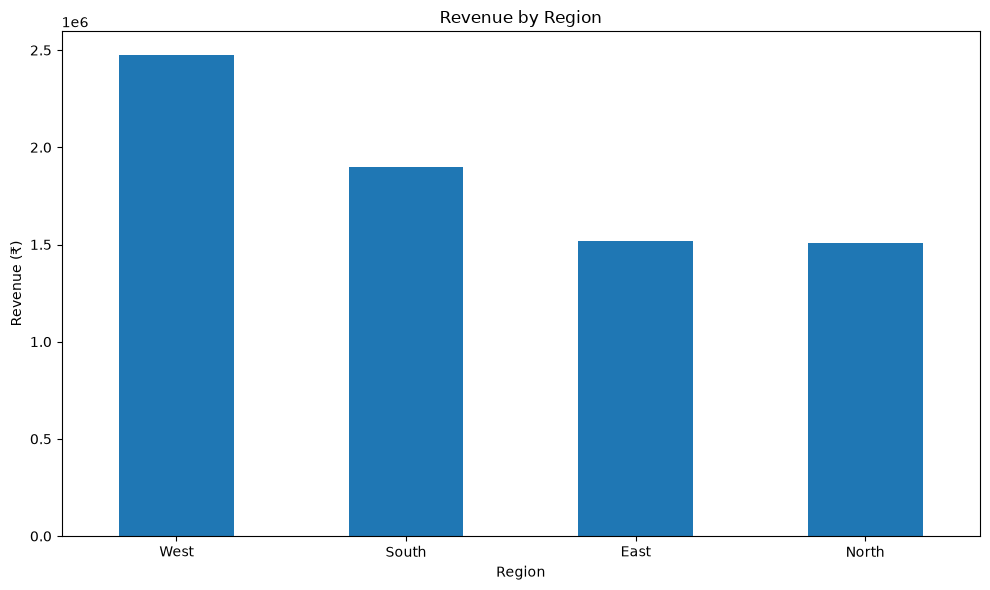

In [44]:
region_revenue.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [45]:
city_revenue = (
    df.groupby('City')['Revenue']
      .sum()
      .sort_values(ascending=False)
)

city_revenue

City
Pune           739601.90
Kolkata        598016.20
Surat          597754.95
Bengaluru      597168.65
Chennai        570959.50
Mumbai         566478.40
Ahmedabad      546152.70
Delhi          436409.80
Lucknow        408358.90
Kochi          392445.90
Patna          378013.80
Ranchi         364171.40
Chandigarh     352376.65
Hyderabad      338212.10
Jaipur         305620.45
Bhubaneswar    176008.70
Unknown         26513.75
Name: Revenue, dtype: float64

In [46]:
top_10_cities = city_revenue.head(10)

top_10_cities

City
Pune         739601.90
Kolkata      598016.20
Surat        597754.95
Bengaluru    597168.65
Chennai      570959.50
Mumbai       566478.40
Ahmedabad    546152.70
Delhi        436409.80
Lucknow      408358.90
Kochi        392445.90
Name: Revenue, dtype: float64

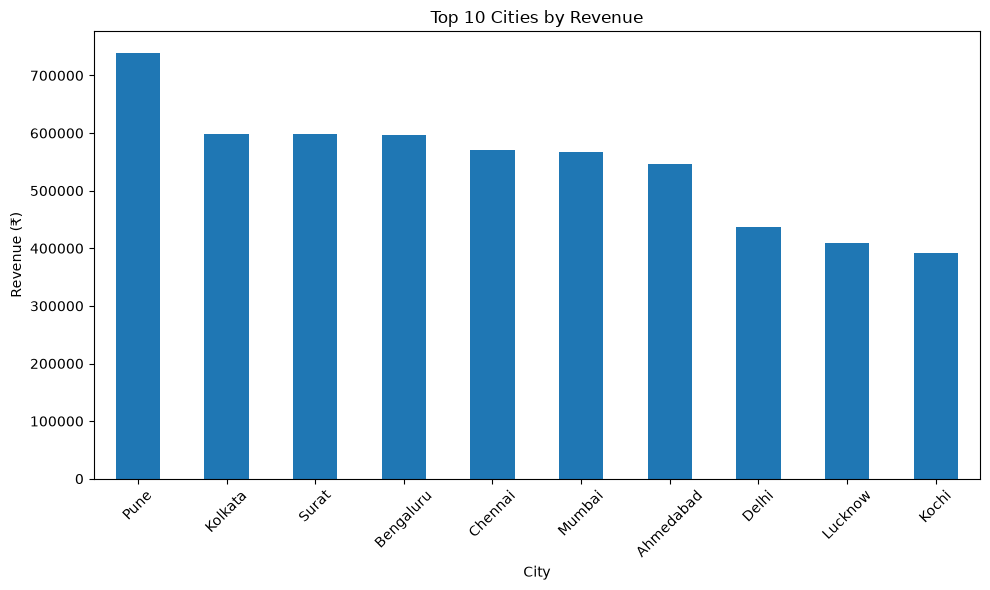

In [47]:
top_10_cities.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Top 10 Cities by Revenue')
plt.xlabel('City')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [48]:
top_10_products_revenue = (
    df.groupby('Product')['Revenue']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_10_products_revenue

Product
Air Fryer              822375.45
Smart Watch            508229.75
Cookware Set           474281.40
Mixer Grinder          427055.55
Wireless Headphones    366353.40
Running Shoes          365128.25
Jeans                  304891.35
Electric Kettle        303041.55
Bluetooth Speaker      302648.60
Cricket Bat            302149.25
Name: Revenue, dtype: float64

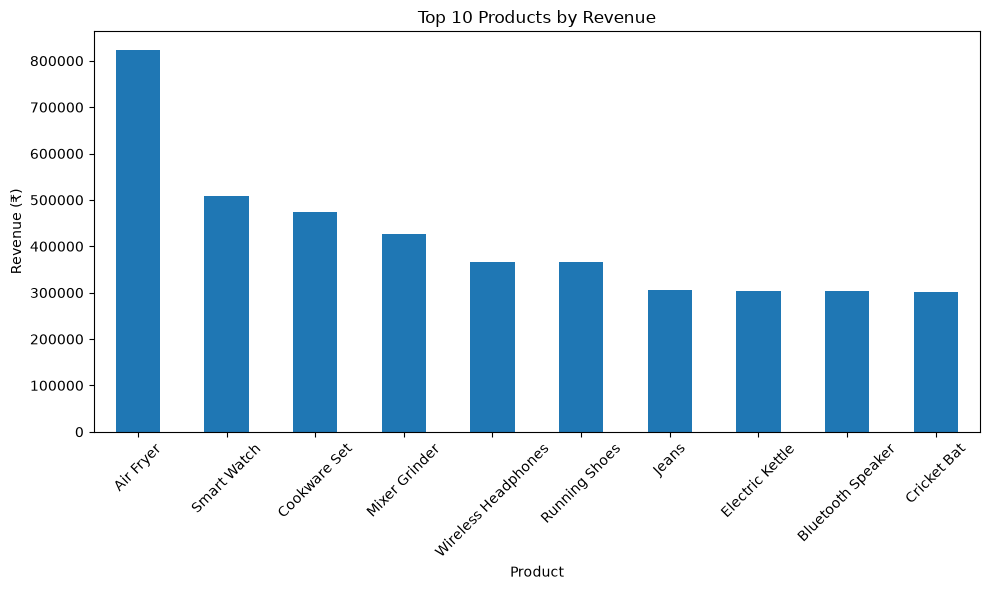

In [49]:
top_10_products_revenue.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Product')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [50]:
top_10_products_profit = (
    df.groupby('Product')['Profit']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_10_products_profit

Product
Air Fryer              235575.45
Smart Watch            160629.75
Cookware Set           141781.40
Running Shoes          139028.25
Wireless Headphones    127853.40
Backpack               116153.55
Jeans                  116141.35
Bluetooth Speaker      115198.60
Mixer Grinder          112455.55
Cricket Bat            111399.25
Name: Profit, dtype: float64

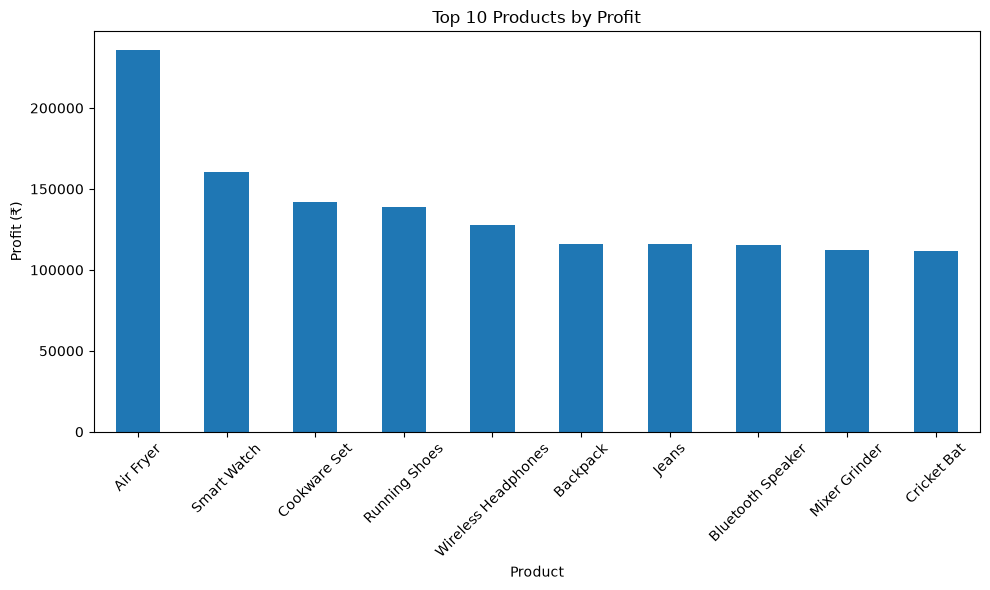

In [51]:
top_10_products_profit.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Top 10 Products by Profit')
plt.xlabel('Product')
plt.ylabel('Profit (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [52]:
lowest_products = (
    df.groupby('Product')
      .agg(
          Revenue=('Revenue', 'sum'),
          Profit=('Profit', 'sum')
      )
      .sort_values('Revenue')
      .head(10)
)

lowest_products

,Revenue,Profit
Product,,
Face Wash,53867.05,24367.05
Coffee 500g,69785.15,24485.15
Premium Rice 5kg,84404.25,21044.25
Football,85664.25,38664.25
Yoga Mat,91248.50,40848.50
Organic Flour 5kg,96828.35,27628.35
Storage Container Set,127622.25,51722.25
USB-C Charger,129590.85,58940.85
Cooking Oil 5L,149998.15,31698.15


In [53]:
df['Month'] = df['Order Date'].dt.to_period('M')

## Time Analysis

This analysis evaluates sales performance over time using monthly revenue, profit, and order volume.

The analysis focuses on:
- Monthly revenue trend
- Monthly profit trend
- Monthly order volume
- Highest revenue month
- Lowest revenue month

In [54]:
monthly_revenue = (
    df.groupby('Month')['Revenue']
      .sum()
)

monthly_revenue

Month
2025-01    370452.90
2025-02    361631.20
2025-03    384139.45
2025-04    452265.30
2025-05    410763.00
2025-06    442661.00
2025-07    345785.95
2025-08    404947.80
2025-09    340585.75
2025-10    319525.50
2025-11    408888.80
2025-12    320868.55
2026-01    443472.75
2026-02    242841.50
2026-03    310518.45
2026-04    324619.55
2026-05    324272.10
2026-06    415912.50
2026-07    391237.55
2026-08    378874.15
Freq: M, Name: Revenue, dtype: float64

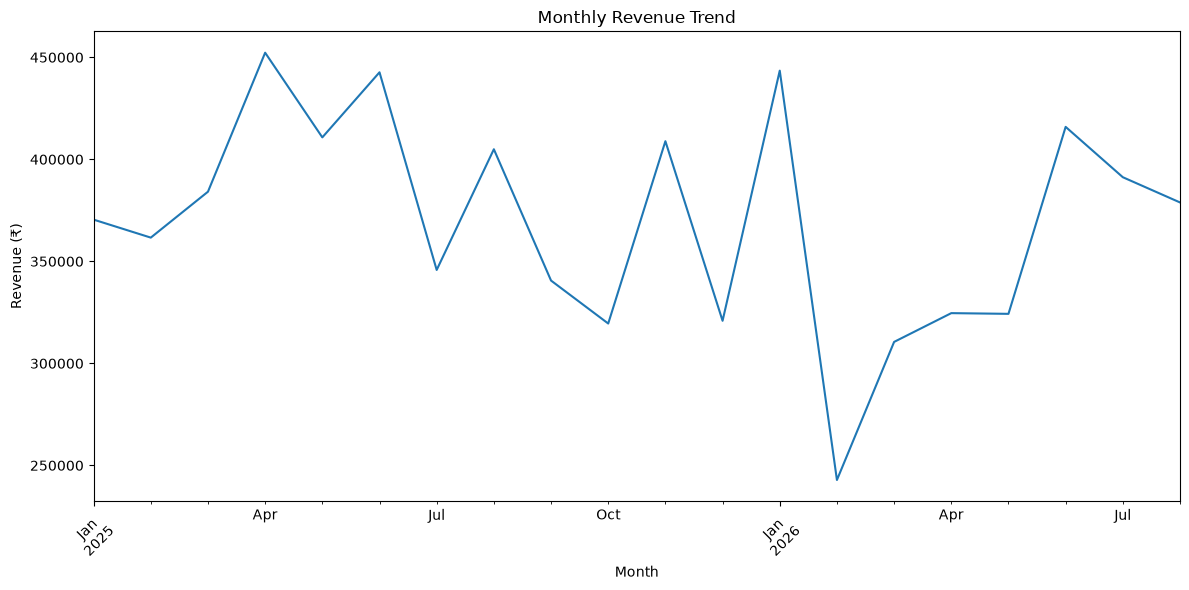

In [55]:
monthly_revenue.plot(
    figsize=(12, 6)
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [56]:
monthly_profit = (
    df.groupby('Month')['Profit']
      .sum()
)

monthly_profit

Month
2025-01    134752.90
2025-02    125461.20
2025-03    137989.45
2025-04    161305.30
2025-05    142193.00
2025-06    152921.00
2025-07    118085.95
2025-08    145117.80
2025-09    118445.75
2025-10    110575.50
2025-11    133778.80
2025-12    114698.55
2026-01    153572.75
2026-02     88511.50
2026-03    107978.45
2026-04    113959.55
2026-05    112732.10
2026-06    145692.50
2026-07    135197.55
2026-08    131894.15
Freq: M, Name: Profit, dtype: float64

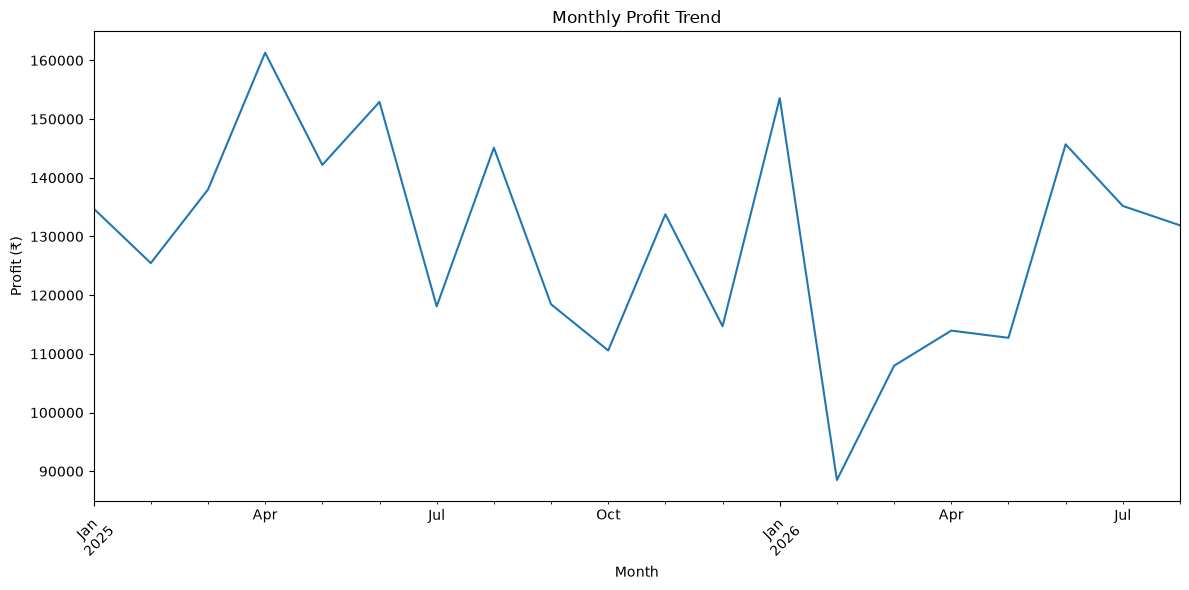

In [57]:
monthly_profit.plot(
    figsize=(12, 6)
)

plt.title('Monthly Profit Trend')
plt.xlabel('Month')
plt.ylabel('Profit (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [58]:
monthly_orders = (
    df.groupby('Month')['Order ID']
      .nunique()
)

monthly_orders

Month
2025-01    101
2025-02     97
2025-03    110
2025-04    109
2025-05     98
2025-06    105
2025-07    106
2025-08    111
2025-09     94
2025-10     87
2025-11    104
2025-12     96
2026-01    106
2026-02     82
2026-03     94
2026-04     90
2026-05     98
2026-06     93
2026-07    115
2026-08     89
Freq: M, Name: Order ID, dtype: int64

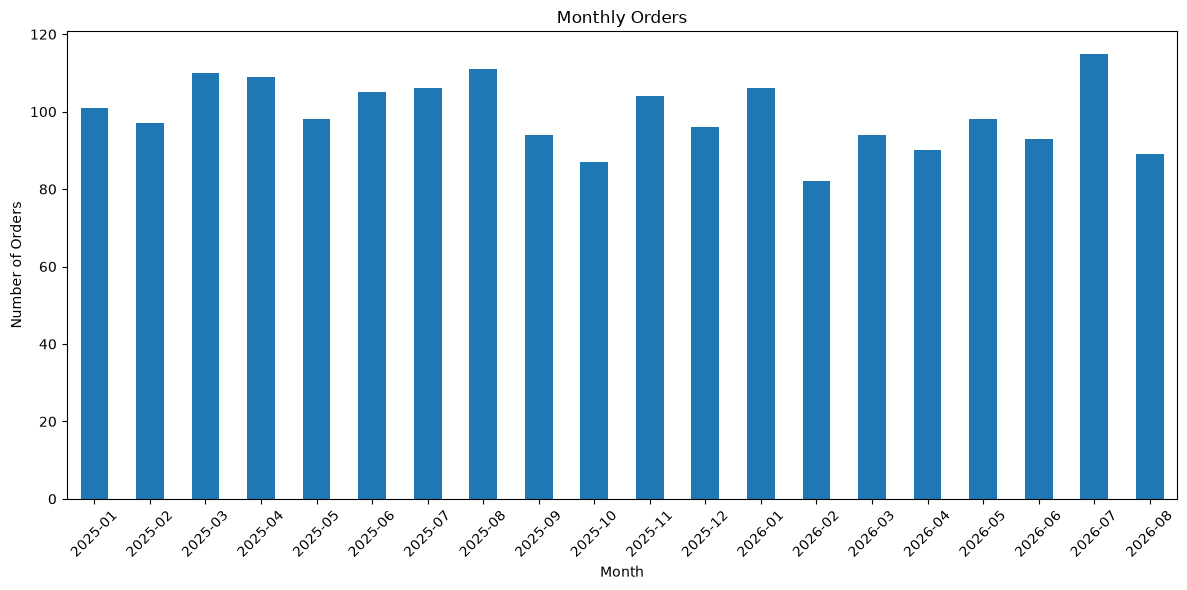

In [59]:
monthly_orders.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Monthly Orders')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [60]:
highest_revenue_month = monthly_revenue.idxmax()
highest_revenue_value = monthly_revenue.max()

lowest_revenue_month = monthly_revenue.idxmin()
lowest_revenue_value = monthly_revenue.min()

print("Highest Revenue Month:", highest_revenue_month)
print("Revenue:", highest_revenue_value)

print("\nLowest Revenue Month:", lowest_revenue_month)
print("Revenue:", lowest_revenue_value)

Highest Revenue Month: 2025-04
Revenue: 452265.3

Lowest Revenue Month: 2026-02
Revenue: 242841.5


## Sales Channel Analysis

This analysis compares sales performance across different sales channels.

The analysis focuses on:
- Orders by sales channel
- Revenue by sales channel
- Profit by sales channel
- Units sold by sales channel
- Comparison of Online and Offline performance

In [61]:
channel_analysis = (
    df.groupby('Sales Channel')
      .agg(
          Revenue=('Revenue', 'sum'),
          Profit=('Profit', 'sum'),
          Orders=('Order ID', 'nunique'),
          Units=('Quantity', 'sum')
      )
      .sort_values('Revenue', ascending=False)
)

channel_analysis

,Revenue,Profit,Orders,Units
Sales Channel,,,,
Online,4671139.55,1632329.55,1257,2640
Offline,2723124.20,952534.20,728,1531


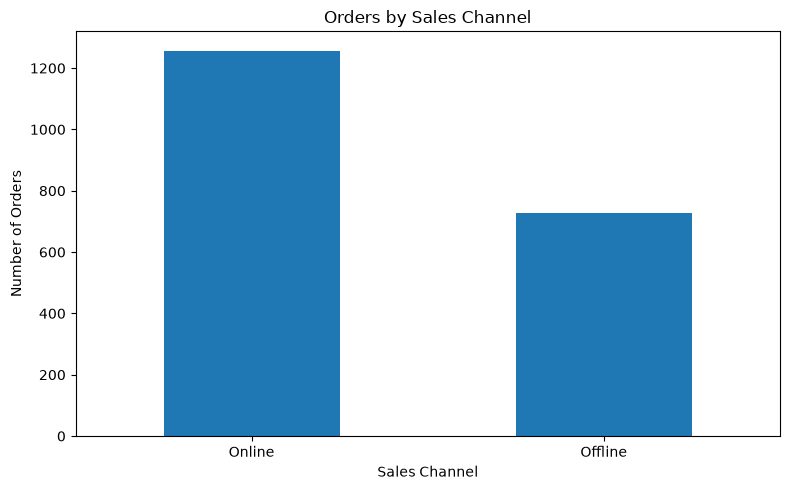

In [62]:
channel_analysis['Orders'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Orders by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Sales Channel Analysis

This analysis compares sales performance across different sales channels.

The analysis focuses on:
- Orders by sales channel
- Revenue by sales channel
- Profit by sales channel
- Units sold by sales channel
- Comparison of Online and Offline performance

In [63]:
top_10_customers = (
    df.groupby(['Customer ID', 'Customer Name'])['Revenue']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_10_customers

Customer ID  Customer Name  
CUST0447     Meera Mehta        64453.75
CUST0201     Sakshi Sharma      54803.50
CUST0040     Isha Nair          52324.90
CUST0021     Nisha Jadhav       48936.95
CUST0063     Sneha More         47979.60
CUST0206     Vivaan Patil       47052.65
CUST0296     Ananya Kulkarni    46335.55
CUST0121     Priya Nair         46239.65
CUST0428     Rahul Joshi        45800.95
CUST0203     Isha Mehta         44182.95
Name: Revenue, dtype: float64

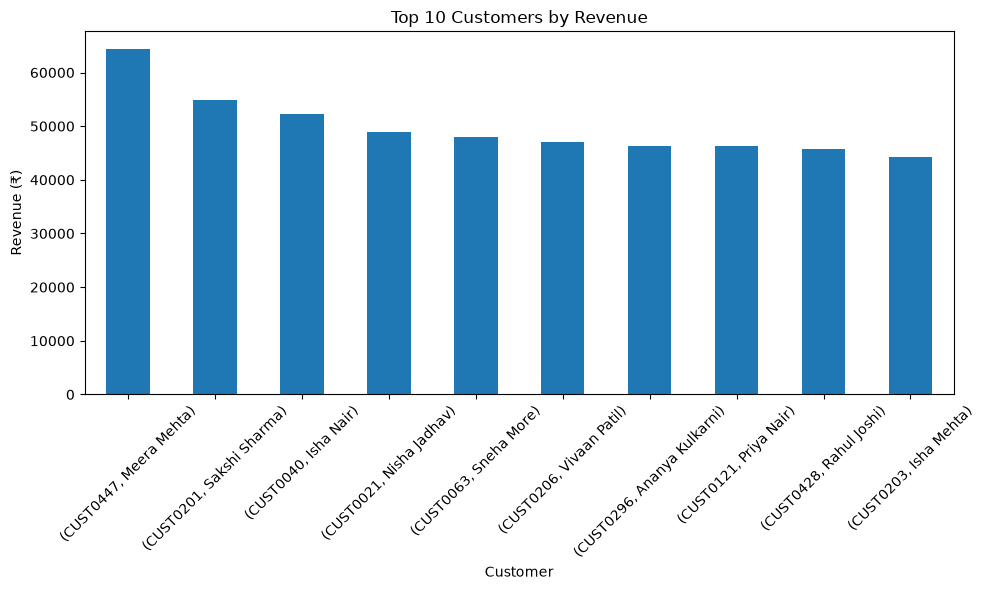

In [64]:
top_10_customers.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Customer')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [65]:
customer_orders = (
    df.groupby('Customer ID')['Order ID']
      .nunique()
)

repeat_customers = (customer_orders > 1).sum()
one_time_customers = (customer_orders == 1).sum()

print("Repeat Customers:", repeat_customers)
print("One-Time Customers:", one_time_customers)

Repeat Customers: 422
One-Time Customers: 23


In [66]:
customer_spending = (
    df.groupby('Customer ID')['Revenue']
      .sum()
)

average_customer_spending = customer_spending.mean()

print(
    "Average Customer Spending: ₹",
    round(average_customer_spending, 2)
)

Average Customer Spending: ₹ 16616.32


## EDA Summary

The Exploratory Data Analysis was performed to understand overall sales performance, product performance, geographical trends, time-based trends, sales channel performance, and customer behavior.

Key performance indicators include:
- Total Revenue
- Total Profit
- Total Orders
- Total Units Sold
- Average Order Value (AOV)
- Profit Margin

The analysis also identified top-performing products, categories, regions, cities, sales channels, and customers.

In [67]:
kpi_summary = {
    'Total Revenue': total_revenue,
    'Total Profit': total_profit,
    'Total Orders': total_orders,
    'Total Units Sold': total_units,
    'Average Order Value': aov,
    'Profit Margin %': profit_margin
}

kpi_summary

{'Total Revenue': np.float64(7394263.75),
 'Total Profit': np.float64(2584863.75),
 'Total Orders': 1985,
 'Total Units Sold': np.int64(4171),
 'Average Order Value': np.float64(3725.0698992443326),
 'Profit Margin %': np.float64(34.957689330462415)}

## Business Insights

### 1. Overall Business Performance
The business generated total revenue of ₹7.39 million and total profit of ₹2.58 million, with an overall profit margin of 34.96%.

### 2. Category Performance
Home & Kitchen generated the highest revenue among all categories, indicating strong customer demand for these products.

### 3. Category Profitability
Fashion achieved the highest profit margin of approximately 40.02%, making it one of the most profitable categories.

### 4. Low-Margin Category
Grocery had the lowest profit margin at approximately 26.87%, indicating a need to review pricing, costs, or discounts.

### 5. Regional Performance
The West region generated the highest revenue of approximately ₹2.47 million, making it the strongest-performing region.

### 6. Product Performance
Air Fryer was the highest-revenue product, generating approximately ₹822,375 in revenue.

### 7. Sales Channel Performance
Online sales generated higher revenue and more orders than offline sales, showing stronger performance through the online channel.

### 8. Customer Behavior
The majority of customers were repeat customers, indicating good customer retention and opportunities for loyalty-focused strategies.

### 9. City Performance
Pune was the highest-revenue city, generating approximately ₹739,602 in sales.

### 10. Monthly Performance
Monthly sales varied significantly over the analysis period. April 2025 recorded the highest monthly revenue, while February 2026 recorded the lowest.

### 4.2 Export Cleaned Dataset

The cleaned dataset was saved separately to preserve the original raw dataset and maintain reproducibility.

In [68]:
df.to_csv(
    "../data/cleaned_sales_data.csv",
    index=False
)

print("Final cleaned dataset saved successfully!")

Final cleaned dataset saved successfully!
